<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 20 · Reproduce research Hamiltonians: Bernevig, Vishwanath and Sachdev

Each section builds a model, solves it, and compares with the published number.
`python -m hopforge.benchmarks` runs all of these checks.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import manybody as MB, moire as MO

## 1. Higher-order TI: Benalcazar-Bernevig-Hughes quadrupole (Science 2017)

nested Wilson loop p_y^{ν_x} = 0.5


corner charge = -0.499


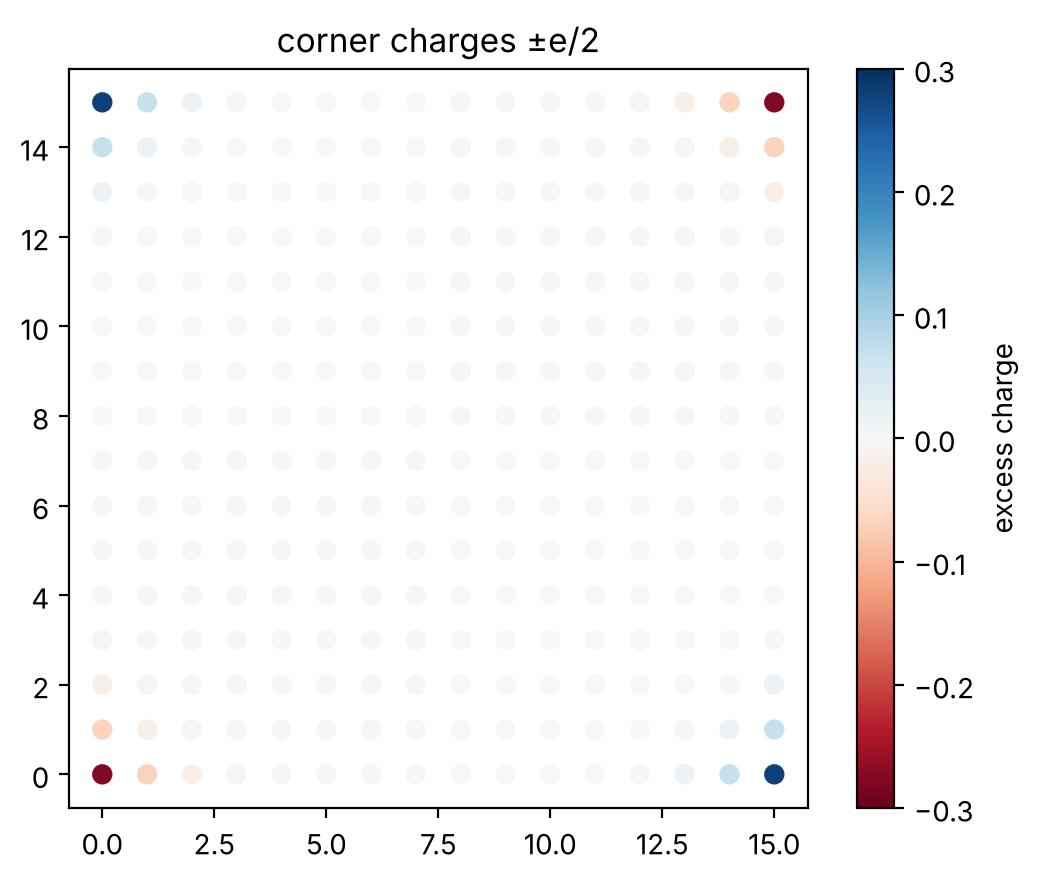

In [2]:
b = M.bbh_quadrupole(gamma=0.5)
print("nested Wilson loop p_y^{ν_x} =", hf.nested_wilson_loop(b, 2, 0))
f = M.bbh_quadrupole(gamma=0.5, delta=1e-3).finite(16)
E, V = np.linalg.eigh(f.hamiltonian())
rho = (np.abs(V[:, :f.nbands // 2])**2).sum(1).reshape(-1, 4).sum(1) - 2
P = f.lat.positions[::4]
plt.scatter(P[:, 0], P[:, 1], c=rho, cmap="RdBu", s=40, vmin=-0.3, vmax=0.3); plt.colorbar(label="excess charge")
plt.title("corner charges ±e/2"); plt.gca().set_aspect("equal")
print("corner charge =", round(rho[(P[:, 0] > 7.5) & (P[:, 1] > 7.5)].sum(), 3))

## 2. Fractional Chern insulator (Regnault & Bernevig, PRX 2011)

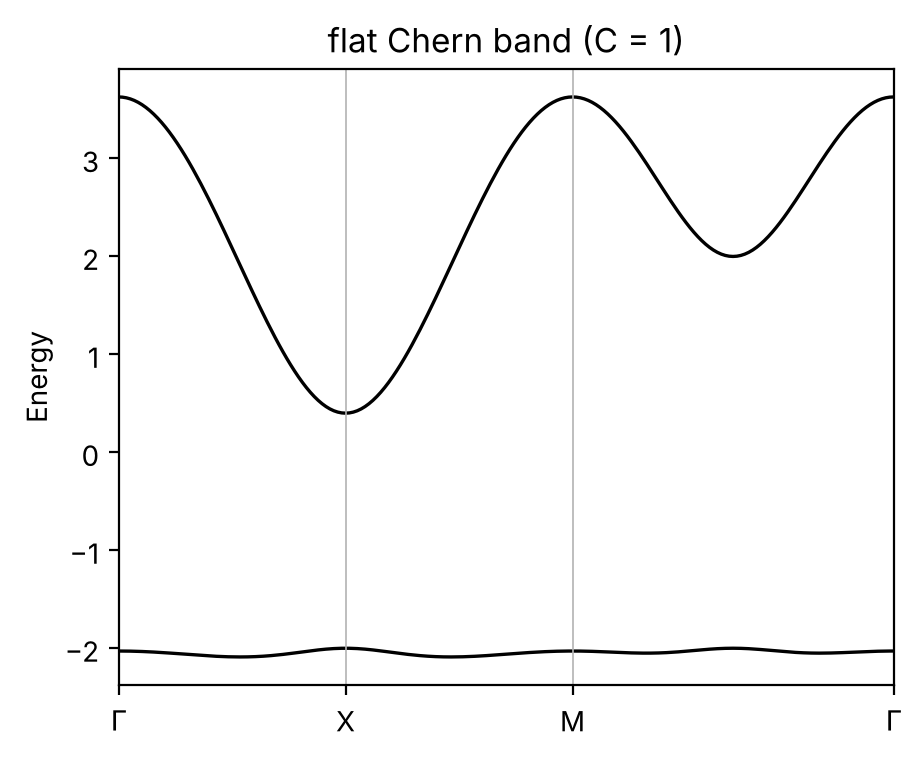

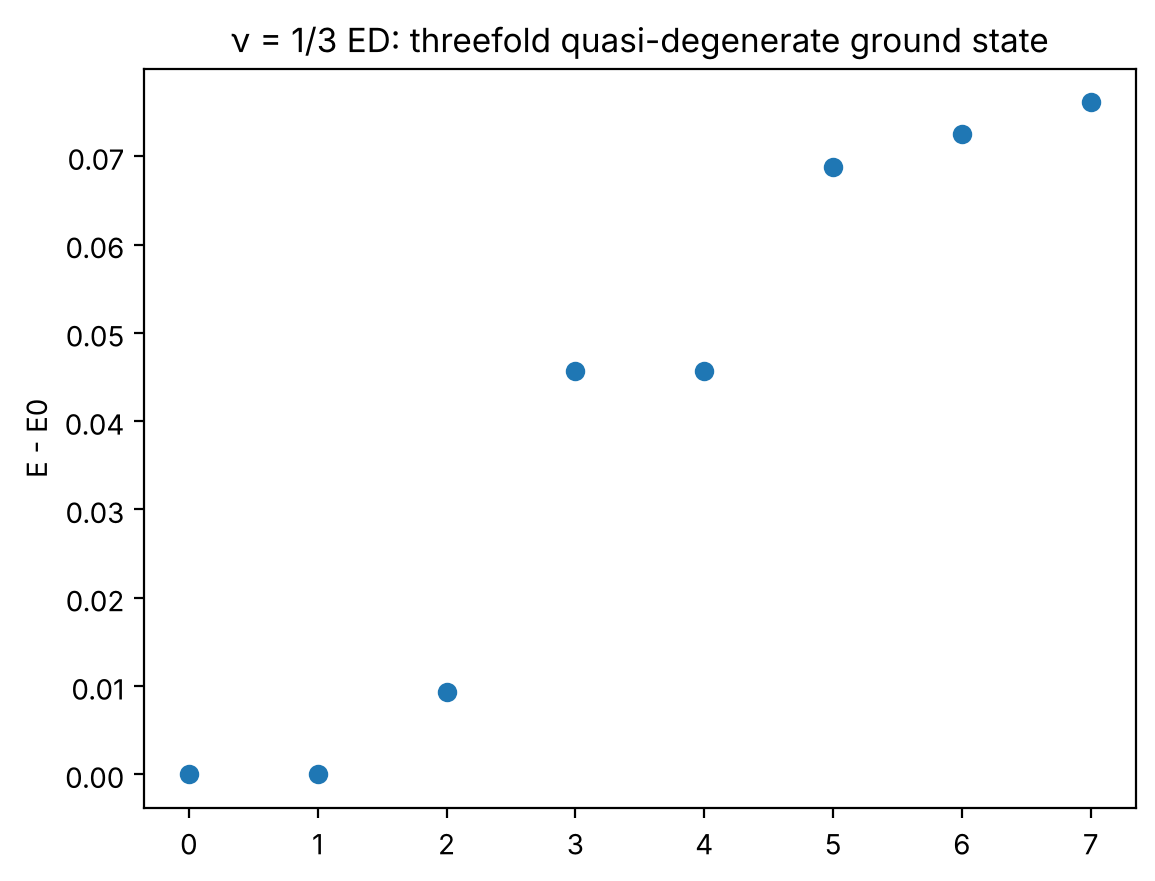

In [3]:
cb = M.checkerboard_chern()
cb.plot_bands(title="flat Chern band (C = 1)")
Es = MB.Fermions(cb.supercell([3, 4]), V=[1.0]).spectrum(4, k=8)
plt.figure(); plt.plot(Es - Es[0], "o"); plt.title("ν = 1/3 ED: threefold quasi-degenerate ground state"); plt.ylabel("E - E0");

## 3. Twisted bilayer graphene: chiral magic angle (Tarnopolsky, Kruchkov & Vishwanath, PRL 2019)

first magic α (chiral): 0.5856704733626232 -> θ ≈ 1.063 deg


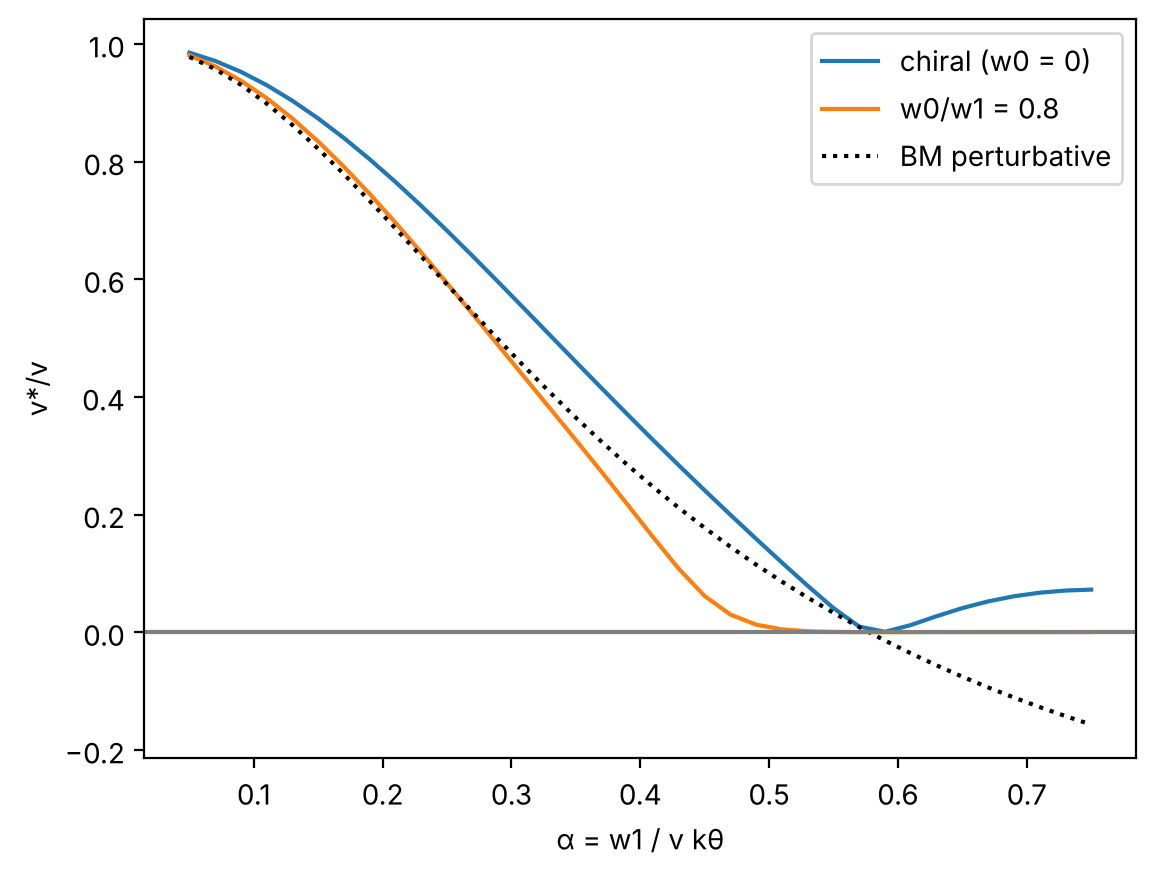

In [4]:
al = np.linspace(0.05, 0.75, 36)
plt.plot(al, MO.velocity_curve(al, 0.0, n_jobs=-1), label="chiral (w0 = 0)")
plt.plot(al, MO.velocity_curve(al, 0.8, n_jobs=-1), label="w0/w1 = 0.8")
plt.plot(al, (1 - 3*al**2)/(1 + 6*al**2), "k:", label="BM perturbative")
plt.axhline(0, c="gray"); plt.legend(); plt.xlabel("α = w1 / v kθ"); plt.ylabel("v*/v")
print("first magic α (chiral):", MO.magic_angles(0.0, n=29)[0], "-> θ ≈", round(MO.alpha_to_theta(0.586), 3), "deg")

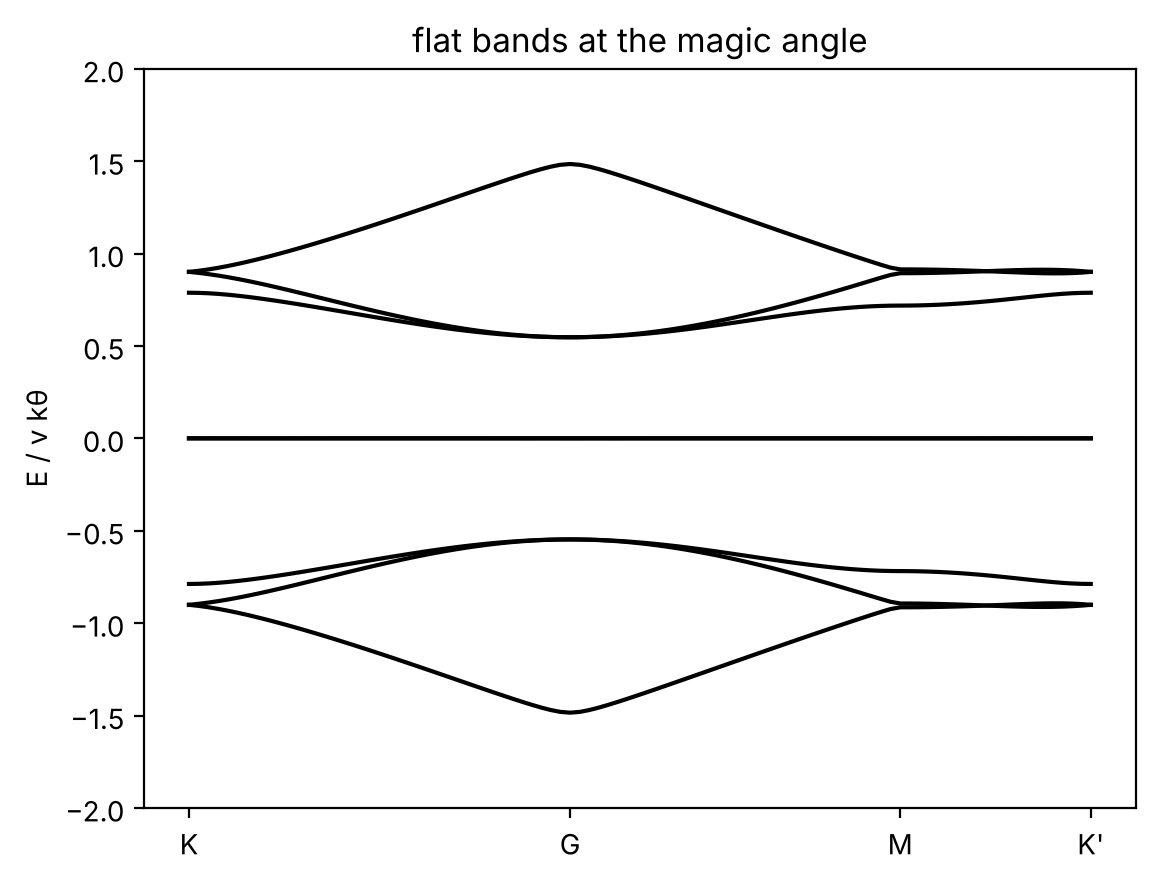

In [5]:
x, E, ticks, labels = MO.BistritzerMacDonald(0.586, 0.0).bands(n=80, nbands=8, n_jobs=-1)
plt.plot(x, E, "k"); plt.xticks(ticks, labels); plt.ylim(-2, 2); plt.ylabel("E / v kθ")
plt.title("flat bands at the magic angle");

## 4. Sachdev-Ye-Kitaev model: ground-state energy and random-matrix level statistics

extrapolated E0/N = -0.0411 (large-N: -0.0406)


N = 16 (N mod 8 = 0): <r> = 0.548


N = 18 (N mod 8 = 2): <r> = 0.602


N = 20 (N mod 8 = 4): <r> = 0.671


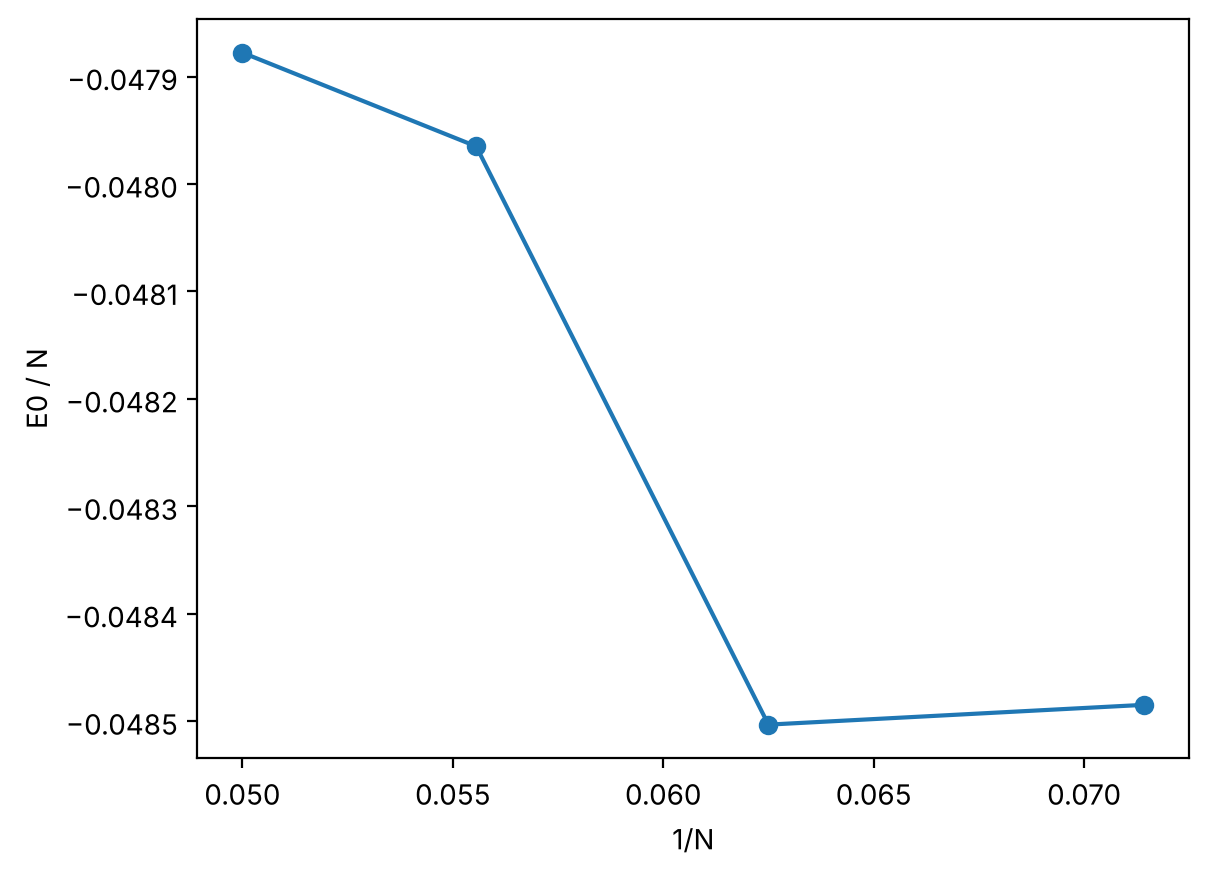

In [6]:
Ns = [14, 16, 18, 20]
E = [np.mean([MB.SYK(N, seed=s).ground_energy() / N for s in range(6)]) for N in Ns]
plt.plot(1 / np.array(Ns), E, "o-"); plt.xlabel("1/N"); plt.ylabel("E0 / N")
c = np.polyfit(1 / np.array(Ns), E, 2); print("extrapolated E0/N =", round(c[-1], 4), "(large-N: -0.0406)")
for N in (16, 18, 20):
    print(f"N = {N} (N mod 8 = {N % 8}): <r> = {MB.syk_level_statistics(N, 10):.3f}")

## 5. Quantum criticality (Sachdev, Quantum Phase Transitions): Ising chain against the exact solution

In [7]:
for h in (0.5, 1.0, 2.0):
    E = MB.PauliModel.transverse_field_ising(12, 1.0, h).ground_state()[0]
    print(f"h = {h}: ED {E:.10f}   Pfeuty exact {MB.tfim_exact_energy(12, 1.0, h):.10f}")

h = 0.5: ED -12.7625691510   Pfeuty exact -12.7625691510


h = 1.0: ED -15.3225951511   Pfeuty exact -15.3225951511
h = 2.0: ED -25.5251383020   Pfeuty exact -25.5251383020


## 6. Kitaev honeycomb spin model (exact ground state on a small cluster)

In [8]:
cl = M.honeycomb().supercell([2, 2])
kh = MB.PauliModel.kitaev_honeycomb(cl, 1.0, 1.0, 1.0)
E0 = kh.ground_state()[0]
print("8-site Kitaev cluster: E0 / site =", E0 / cl.norb)

8-site Kitaev cluster: E0 / site = -0.8660254037844383


---
## Quiz 20: Research models

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [9]:
quiz = hf.Quiz(20)
quiz.interactive()

In [10]:
quiz.show()

=== Quiz 20: Research models: Bernevig, Vishwanath, Sachdev ===

Q1. The BBH quadrupole insulator has
   (a) a Chern number 1
   (b) gapless edges
   (c) no gap
   (d) quantised corner charges +-e/2 and gapped edges

Q2. The quadrupole invariant is detected by
   (a) the DOS
   (b) nested Wilson loops (Wannier-sector polarisation 1/2)
   (c) the Chern number
   (d) the Fermi level

Q3. A fractional Chern insulator at nu = 1/3 on a torus shows
   (a) no gap
   (b) a Fermi surface
   (c) a threefold quasi-degenerate ground state
   (d) a unique ground state

Q4. Flat Chern bands help FCIs because
   (a) they are metallic
   (b) interactions dominate over the small kinetic bandwidth
   (c) they have no gap
   (d) they have C = 0

Q5. The chiral limit of TBG sets
   (a) w1 = 0
   (b) the AA tunnelling w0 = 0
   (c) theta = 0
   (d) v = 0

Q6. The first chiral magic angle is at alpha =
   (a) 0.1
   (b) 1.0
   (c) 0.586
   (d) 2.0

Q7. At the magic angle the Dirac velocity
   (a) doubles
  

In [11]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0